# RS full-test rate–distortion results
1217-image full test set with the completed Hybrid and comparison-method results.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
DATA = Path('../data/full_test_rd_all_methods.csv')
rd = pd.read_csv(DATA)
data = rd[rd.Dataset.eq('rs')].sort_values(['Method', 'bpp'])
display(data[['Method','Lambda','images','bpp','psnr','ms_ssim_db']].reset_index(drop=True))

,Method,Lambda,images,bpp,psnr,ms_ssim_db
0,elic,16384,1217,0.097869,48.167234,23.660542
1,elic,32768,1217,0.182256,50.042888,25.763425
2,elic,65536,1217,0.306333,51.888581,27.680210
3,elic,131071,1217,0.476949,53.331755,29.368341
4,elic,262144,1217,0.720537,54.958707,31.452550
...,...,...,...,...,...,...
61,rwk,65536,1217,0.334543,52.715454,28.542721
62,rwk,131071,1217,0.531450,54.036886,30.256784
63,rwk,262144,1217,0.836559,56.091722,32.543530
64,rwk,393216,1217,1.053710,56.887457,33.564076


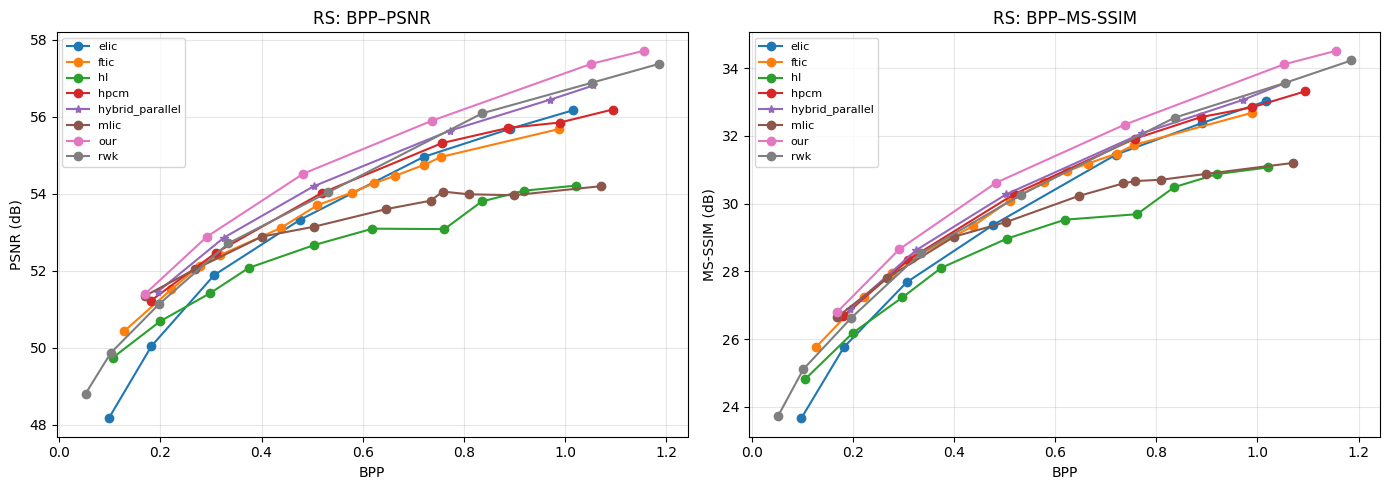

In [2]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for method, group in data.groupby('Method'):
    group = group.sort_values('bpp')
    marker = '*' if method == 'hybrid_parallel' else 'o'
    axes[0].plot(group.bpp, group.psnr, marker=marker, label=method)
    axes[1].plot(group.bpp, group.ms_ssim_db, marker=marker, label=method)
axes[0].set(xlabel='BPP', ylabel='PSNR (dB)', title='RS: BPP–PSNR')
axes[1].set(xlabel='BPP', ylabel='MS-SSIM (dB)', title='RS: BPP–MS-SSIM')
for ax in axes:
    ax.grid(alpha=.3); ax.legend(fontsize=8)
fig.tight_layout(); plt.show()